# TL;DR


load sklearn datasets

```python
from sklearn import datasets 
newsgroups = datasets.fetch_20newsgroups_vectorized()
wine = datasets.load_wine()
X, y = newsgroups.data, newsgroups.target
X, y = wine.data, wine.target



Support Vector Machine

```python
from sklearn.svm import LinearSVC, SVC

Decision boundary: different classification boundaries

```python
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.linear_model import LogisticRegression
import matplotlib.pyplot as plt

lr = LogisticRegression().fit(X,y)

DecisionBoundaryDisplay.from_estimator( # chart with boundaries: each class boudnary a color
    lr,
    X,
    response_method="predict",
    cmap=plt.cm.coolwarm,
)
plt.scatter(X[:,0], X[:,1], c = y, cmap=plt.cm.coolwarm) # plot values
```

dot operation: for X * coeff + intercept

```python
x = np.arange(3)
y = np.arange(3,6)
x@y == np.sum(x*y) # dot product here

numpy argsort (confusing!)

```python
import numpy as np 
X, y = digits.data, digits.target 

lr = LogisticRegression(max_iter = 10000)
lr.fit(X,y) 

proba = lr.predict_proba(X) # for each row, each value is the odds of being a number, from 0 to 9

proba_inds = np.argsort(np.max(proba, axis = 1))
```
X: each row has data that codes a digit. The targes are y. 
proba: list of lists. Each row has 10 value: probability of each digit being correct.
proba_inds: np.argsort returns the same order of lists, but each list within is sorted: higest to lowest
This means that, for each row, the first value is the most probable number

More details on chapter 3, on logistic regression & probabilities





Multi class Logistic Regression:
```python
from sklearn.linear_model import LogisticRegression
lr_ovr = LogisticRegression(multi_class = 'ovr')
lr_mn = LogisticRegression(multi_class = 'multinomial')


# 1: Applying logistic regression and SVM


Quick review of KNN, train test split, score
```python

# KNN
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors = 1)

# Train Test Split
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y)

# Applying KNN & train test splt
knn.fit(X_train,y_train)
y_pred = knn.predict(X_test)
score = knn.score(X_test,y_test)



Applying logistic regression and SVM

```python
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()
lr.fit(X_train, y_train)
lr.predict(X_test)
lr.score(X_test, y_test)
```



Loading wine data:
```python
import sklearn.datasets
wine = sklearn.datasets.load_wine()
```



Using LinearSVC (more on that later)
```python
from sklearn.svm import LinearSVC
svm = LinarSVC()
svm.fit(X_train, y_train)
svm.score(X_test, y_test)
```


Underfitting: 
- model is too simple; low training accuracy  
(lr.score(X_train, y_train) low)

Overfitting: 
- Model is too complex; low test accuracy  
(lr.score(X_test, y_test) low)

Let's practice!

In [1]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn import datasets 
from sklearn.model_selection import train_test_split

digits = datasets.load_digits()
X_train, X_test, y_train, y_test = train_test_split(digits.data, digits.target)

# Logistic regression
lr = LogisticRegression( max_iter = 10000000)
lr.fit(X_train, y_train)

# SVM
svm = LinearSVC(max_iter = 10000000)
svm.fit(X_train, y_train)

print('accuracy:')
for model in ['lr', 'svm']:
    print(model, 'train data', globals()[model].score(X_train, y_train))
    print(model, 'test data', globals()[model].score(X_test, y_test))


accuracy:
lr train data 1.0
lr test data 0.9644444444444444
svm train data 0.9970304380103935
svm test data 0.9511111111111111


Support Vector Machine, from Bing:

Sure! Support Vector Machines (SVM) is a type of machine learning algorithm that can be used for classification and regression analysis. The goal of SVM is to find the hyperplane that maximizes the margin between the two classes. The margin is defined as the distance between the hyperplane and the closest data points from each class. The hyperplane that maximizes the margin is called the maximum margin hyperplane.

SVMs can be used for both linear and nonlinear classification and regression problems. SVMs are particularly useful when there are many features in the dataset, as they can handle high-dimensional data well.

Sure! Let’s say we have a dataset of two classes of points: red and blue. We want to find a hyperplane that separates the two classes. In two-dimensional space, the hyperplane is a line. The goal of Support Vector Machines (SVM) is to find the line that maximizes the margin between the two classes. The margin is defined as the distance between the line and the closest data points from each class. The hyperplane that maximizes the margin is called the maximum margin hyperplane.

Here’s an example of a hyperplane that separates two classes of points:

Hyperplane example

In this example, the red and blue points represent two different classes. The hyperplane is the line that separates the two classes. The margin is defined as the distance between the line and the closest data points from each class.

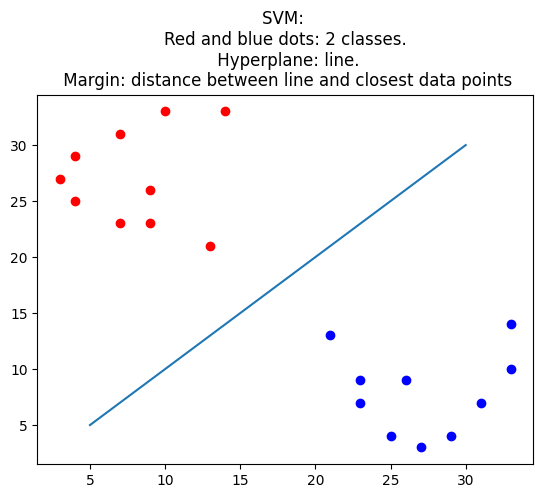

In [15]:
# not from datacamp: Me replicating answer from Bing
import matplotlib.pyplot as plt 
import numpy as np 
x1 = y2 = np.random.randint(2,15,10)
y1 = x2 = np.random.randint(20,35,10)

plt.scatter(x1, y1, c = 'red')
plt.scatter(x2, y2, c = 'blue')
plt.plot([5,30], [5,30])
plt.title('SVM: \nRed and blue dots: 2 classes.\n Hyperplane: line.\n Margin: distance between line and closest data points')
plt.show()

Linear decision boundaries: Vocabulary
- Classification
- Decision boundary
- Linear classifier (ex: Logistic Regression, linear SVM)
- Linearly separable: data set explainable by a linear classifier

Let's practice!

In [51]:
from sklearn import datasets
from sklearn.linear_model import LogisticRegression 
from sklearn.svm import SVC, LinearSVC 
from sklearn.neighbors import KNeighborsClassifier 

wine = datasets.load_wine()
X,y = wine['data'][:128,:2], wine['target'][:128]

classifiers = [LogisticRegression(), LinearSVC(), SVC(), KNeighborsClassifier()]

for c in classifiers:
    c.fit(X,y)

classifiers[1].score(X,y)

f:\git\env\Lib\site-packages\sklearn\svm\_base.py:1244: ConvergenceWarning: Liblinear failed to converge, increase the number of iterations.
  warnings.warn(


0.8984375

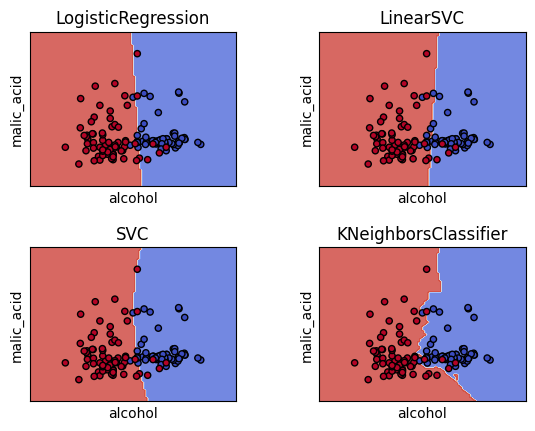

In [66]:
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt
# Set-up 2x2 grid for plotting.
fig, sub = plt.subplots(2, 2)
plt.subplots_adjust(wspace=0.4, hspace=0.4)

X0, X1 = X[:, 0], X[:, 1]

for clf, ax in zip(classifiers, sub.flatten()):
    disp = DecisionBoundaryDisplay.from_estimator(
        clf,
        X,
        response_method="predict",
        cmap=plt.cm.coolwarm,
        alpha=0.8,
        ax=ax,
        xlabel=wine.feature_names[0],
        ylabel=wine.feature_names[1],
    )
    ax.scatter(X0, X1, c=y, cmap=plt.cm.coolwarm, s=20, edgecolors="k")
    ax.set_xticks(())
    ax.set_yticks(())
    ax.set_title(str(clf.__class__).split('.')[-1][:-2])

plt.show()

# 2: Loss functions

Linear classifiers: Prediction equations

Dot products
```python
x = np.arange(3)
y = np.arange(3,6)
x@y == np.sum(x*y) # dot product here

Linear classifier prediction
- raw model output = coefficients * features + intercept
- Linear classifier prediction: compute raw model output, check sign
    - positive: one class
    - negative: other class
- same for logistic regression and linear SVM

```python
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()
lr.fit(X,y)
lr.predict(X)[10] # 0
lr.predict(x)[20] # 1
lr.coef_ @ x[10] + lr.intercept_ # raw model output = -33 = class 0
lr.coef_ @ x[20] + lr.intercept_ # raw model output = 0.8 = class 1
```


Let's practice!

Text(0.5, 1.0, 'Decision Boundary Display: Logistic Regression\n Coefficients were changed manually')

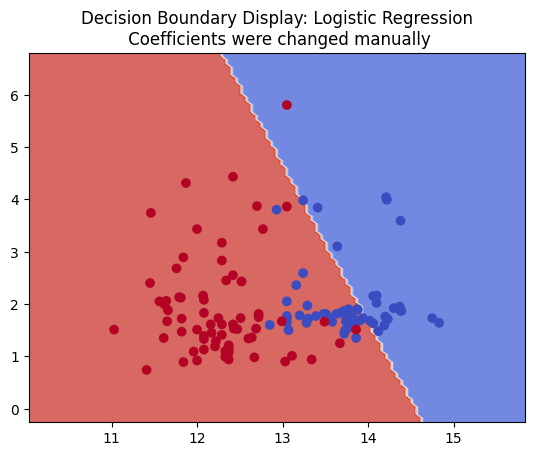

In [1]:
import numpy as np 
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.linear_model import LogisticRegression
from sklearn import datasets 
import matplotlib.pyplot as plt
X, y = datasets.load_wine().data[:128, :2], datasets.load_wine().target[:128]

lr = LogisticRegression()
lr.fit(X,y)

# set the coefficients

lr.coef_ = np.array([[-3,-1]])
# lr.intercept_ = np.array([-3])

DecisionBoundaryDisplay.from_estimator(
    lr,
    X,
    response_method="predict",
    cmap=plt.cm.coolwarm,
    alpha=0.8,
        # ax=ax,
        # xlabel=wine.feature_names[0],
        # ylabel=wine.feature_names[1],
)
plt.scatter(X[:,0], X[:,1], c = y, cmap=plt.cm.coolwarm)
lr.coef_
plt.title('Decision Boundary Display: Logistic Regression\n Coefficients were changed manually')

What is a loss function?

```python
from scipy.optimize import minimize
minimize(np.square, 0).x
minimize(np.square, 2).x


In [3]:
from scipy.optimize import minimize 
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression

diabetes = load_diabetes()
X,y = diabetes.data, diabetes.target

# The squared error, summed over training examples
def my_loss(w):
    s = 0
    for i in range(y.size):
        # get the true and predicted target values for example 'i' 
        y_i_true = y[i]
        y_i_pred = w@X[i]
        s = s + (y_i_true - y_i_pred)**2
    return s
# Returns the w that makes my_loss(w) smallest
w_fit = minimize(my_loss, X[0]).x
print('These are the coefficients generated by the function minimize: ', w_fit)

# compare with scikit-learn's LinearRegression coefficients
lr = LinearRegression(fit_intercept = False).fit(X,y)
print('These are the coefficients from LinearRegression: ', lr.coef_)

These are the coefficients generated by the function minimize:  [  -9.71051459 -240.49348261  520.92143845  324.57925258 -791.69006082
  474.91567324  102.22464841  179.34773313  750.07322073   67.21899052]
These are the coefficients from LinearRegression:  [ -10.0098663  -239.81564367  519.84592005  324.3846455  -792.17563855
  476.73902101  101.04326794  177.06323767  751.27369956   67.62669218]


In [7]:
X[0].size, y.size

(10, 442)

Loss function diagrams

raw model output:
y_axis = loss (ideal: higher on negative x, lower on positive x);
x_axis = raw model output (-2 until 2)
x_axis: 
    - negative = predict -1 (incorrect)
    - positive: predict + 1 (correct)


- 0-1 loss diagram
- linear regression loss diagram
- logistic loss diagram


In [1]:
from sklearn.datasets import load_iris
from scipy.optimize import minimize
from sklearn.linear_model import LogisticRegression
import numpy as np 

iris = load_iris()
X, y = iris.data[:90,:], iris.target[:90]

def log_loss(raw_model_output):
   return np.log(1+np.exp(-raw_model_output))

def my_loss(w):
    s = 0
    for i in range(y.size):
        raw_model_output = w@X[i]
        s = s + log_loss(raw_model_output * y[i])
    return s

# Returns the w that makes my_loss(w) smallest
w_fit = minimize(my_loss, X[0]).x
print(w_fit)

# Compare with scikit-learn's Logistic Regression
lr = LogisticRegression(fit_intercept = False, C = 1000000).fit(X,y)
print(lr.coef_)

[5.1 3.5 1.4 0.2]
[[-2.45752241 -6.16465943 10.4118926   4.56108281]]


# 3: Logistic regression and Relularization



Stuff I don't understand
- regularized logistic regression
- chart: y-axis = coefficient value ; x-axis = coefficient index  
- regularized logistic regression: 
    - higher C = higher coefficient variation
    - lower C = lower coefficient variation (buffer?)

How does regularization affect training accuracy?
```python 
lr_weak_reg = LogisticRegression(C = 100)
lr_strong_reg = LogisticRegression(C =0.01)

lr_weak_reg.fit(X_train, y_train)
lr_strong_reg.fit(X_train, y_train)

lr_weak_reg.score(X_train, y_train) # 1
lr_strong_reg.score(X_train, y_train) # 0.92
```
regularized loss = original loss + large coefficient penalty
- more regularization: lower training accuracy



How does Regularization affect test accuracy?
```python
lr_weak_reg.score(X_test, y_test) # 0.86
lr_strong_reg.score(X_test, y_test) # 0.88
```
more regularization: (almost always) higher test accuracy

L1 vs L2 regularization
- Lasso = linreg w/ L1 regularization 
- Ridge = linreg w/ L2 regularization 

```python
lr_L1 = LogisticRegression(solver = 'liblinear', penalty = 'l1')
lr_L2 = LogisticRegression() # penalty = 'l2' by default

lr_L1.fit(X_train, y_train)
lr_L2.fit(X_train, y_train)

plt.plot(lr_L1.coef_.flatten())
plt.plot(lr_L2.coef_.flatten())

Let's practice!

Text(0.5, 1.0, 'small C = underfitting; large C = overfitting')

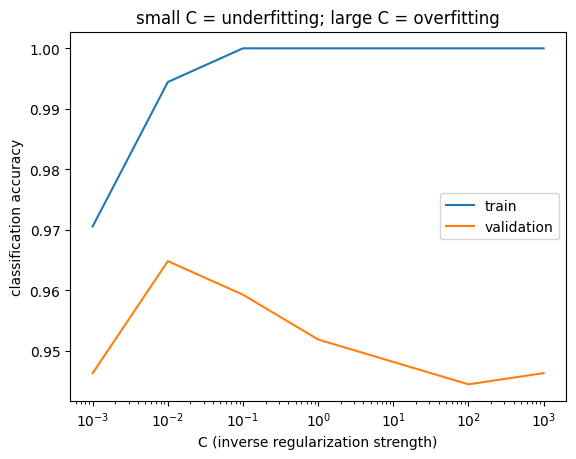

In [35]:
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression 
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt 


digits = load_digits()
X, y = digits.data, digits.target 
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.3)

# train and validation errors lists 
train_errs = []
valid_errs = []

# Loop over values of C_value  
C_values = [0.001, 0.01, 0.1, 1, 10, 100, 1000]
for C_value in C_values :
    lr = LogisticRegression(C = C_value, random_state = 42, max_iter = 100000)
    lr.fit(X_train, y_train)
    train_errs.append(lr.score(X_train, y_train))
    valid_errs.append(lr.score(X_test, y_test))

# Plot results 
plt.semilogx(C_values, train_errs)
plt.semilogx(C_values, valid_errs)
plt.legend(('train','validation'))

plt.ylabel('classification accuracy')
plt.xlabel('C (inverse regularization strength)')
plt.title('small C = underfitting; large C = overfitting')

In [48]:
import numpy as np 

s = np.random.choice(range(10,20), 10, replace = False )
si = np.argsort(s)

print(s)
print(si)
print(np.array([s[i] for i in si]))

[13 18 11 16 10 12 15 14 19 17]
[4 2 5 0 7 6 3 9 1 8]
[10 11 12 13 14 15 16 17 18 19]


Logistic regression and probabilities 

without regularization (C = 10^8)
- coef = 1.55, 1.57
- model intercept: -0.64
- probabilities: are all closer to 0 or 1 (well defined S)

with regularization (C = 1)
- coef = 0.45, 0.64
- model intercept: -0.26
- probabilities: all closer to 0.5 (S closer to a straight line)

get probability:  
- model.pridict_proba(X)

Retrieve max value:
- np.max(model.predict_proba(X))

Time to practice! (terrible exercises...)

coefs:  [[ 0.00222863 -0.00143889]] [-0.23077848]


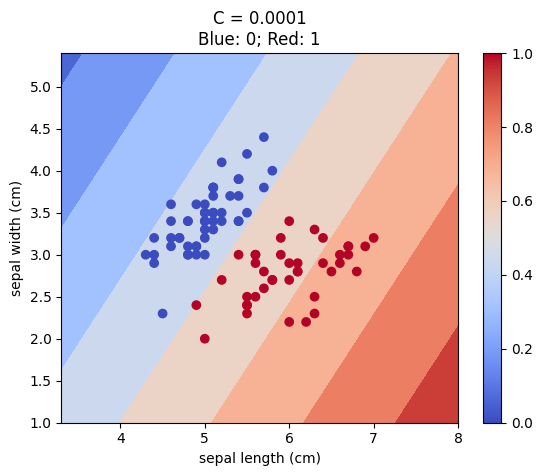

coefs:  [[ 20.56124392 -17.93589524]] [-54.32584766]


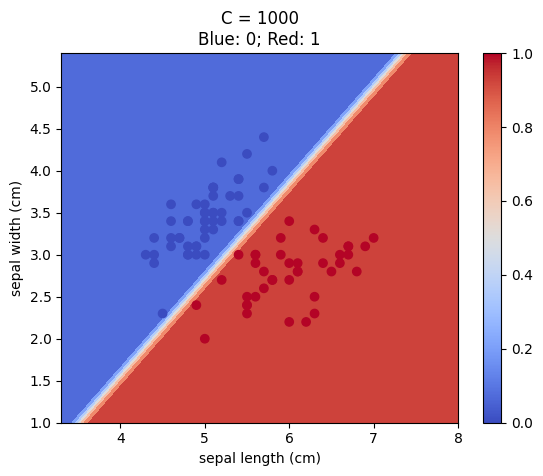

In [187]:
from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.inspection import DecisionBoundaryDisplay

iris = load_iris()
X,y = iris.data[:90,:2], iris.target[:90]
for C in [0.0001, 1000]:
    model = LogisticRegression(C = C) 
    model.fit(X,y)

    prob = model.predict_proba(X) 
    
    DecisionBoundaryDisplay.from_estimator(
        model,
        X,
        response_method="predict_proba",
        cmap=plt.cm.coolwarm,
        # alpha=0.8,
        # colorbar = True,
        # proba = True,
        
            # ax=ax,
            xlabel=iris.feature_names[0],
            ylabel=iris.feature_names[1],
    )
    plt.scatter(X[:,0], X[:,1], c = y, cmap=plt.cm.coolwarm)
    plt.colorbar()
    plt.title(f'C = {model.C}\nBlue: 0; Red: 1')
    print('coefs: ', model.coef_, model.intercept_)
    plt.show()
    

most confident digit


<Figure size 640x480 with 0 Axes>

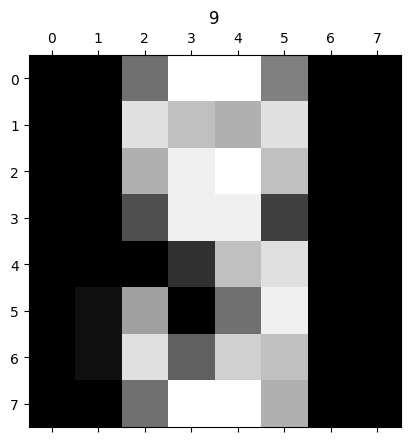

least confident digit


<Figure size 640x480 with 0 Axes>

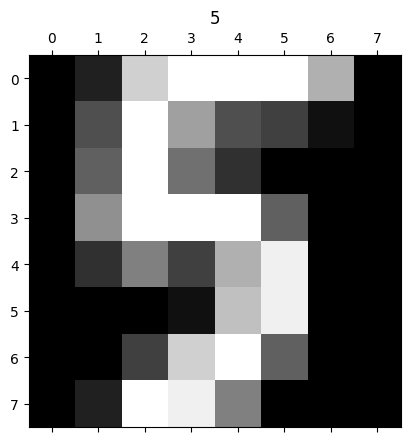

In [186]:
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
digits = load_digits() 
import numpy as np 
X, y = digits.data, digits.target 

lr = LogisticRegression(max_iter = 10000)
lr.fit(X,y) 

proba = lr.predict_proba(X) # for each row, each value is the odds of being a number, from 0 to 9

proba_inds = np.argsort(np.max(proba, axis = 1))

def show_digit(i):
    plt.gray()
    plt.matshow(X[i].reshape(8,8))
    plt.title(y[i])
    plt.show()
print('most confident digit')
show_digit(proba_inds[0])

print('least confident digit')
show_digit(proba_inds[-1])

In [142]:
X.shape, proba.shape, proba_inds.shape 

((1797, 64), (1797, 10), (1797,))

In [183]:
digits.target 

array([0, 1, 2, ..., 8, 9, 8])

In [164]:
proba[1].round(4), y[1]

(array([0., 1., 0., 0., 0., 0., 0., 0., 0., 0.]),
 1,
 array([1658, 1553,    5, ..., 1420, 1625,   32], dtype=int64))

In [179]:
np.max(proba, axis = 1)[-1]

0.9999858102825918

<Figure size 640x480 with 0 Axes>

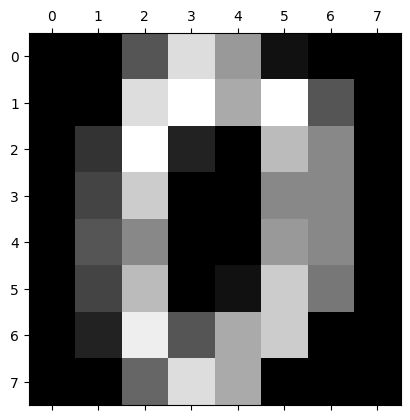

In [138]:
digits.images[0], X[0].reshape(8,8)

(array([[ 0.,  0.,  5., 13.,  9.,  1.,  0.,  0.],
        [ 0.,  0., 13., 15., 10., 15.,  5.,  0.],
        [ 0.,  3., 15.,  2.,  0., 11.,  8.,  0.],
        [ 0.,  4., 12.,  0.,  0.,  8.,  8.,  0.],
        [ 0.,  5.,  8.,  0.,  0.,  9.,  8.,  0.],
        [ 0.,  4., 11.,  0.,  1., 12.,  7.,  0.],
        [ 0.,  2., 14.,  5., 10., 12.,  0.,  0.],
        [ 0.,  0.,  6., 13., 10.,  0.,  0.,  0.]]),
 array([[ 0.,  0.,  5., 13.,  9.,  1.,  0.,  0.],
        [ 0.,  0., 13., 15., 10., 15.,  5.,  0.],
        [ 0.,  3., 15.,  2.,  0., 11.,  8.,  0.],
        [ 0.,  4., 12.,  0.,  0.,  8.,  8.,  0.],
        [ 0.,  5.,  8.,  0.,  0.,  9.,  8.,  0.],
        [ 0.,  4., 11.,  0.,  1., 12.,  7.,  0.],
        [ 0.,  2., 14.,  5., 10., 12.,  0.,  0.],
        [ 0.,  0.,  6., 13., 10.,  0.,  0.,  0.]]))

Multi-class logistic regression 

Combining binary classifiers with one-vs-rest
```python
lr0.fit(X, y == 0)
lr1.fit(X, y == 1)
lr2.fit(X, y == 2)

# get new model output 
lr0.decision_function(X)[0] # 6
lr1.decision_function(X)[0] # -5
lr2.decision_function(X)[0] # -7

### The same as:
lr = LogisticRegression(multi_class = 'ovr')
lr.fit(X,y)
lr.predict(X)[0]

#### Different multi_classes:
lr_ovr = LogisticRegression(multi_class = 'ovr')
lr_mn = LogisticRegression(multi_class = 'multinomial')


One-vs-rest X "Multinomial"/"Softmax"

One-vs-rest: 
- fit a binary classifier for each class
- predict with all, take largest output
- pro: simple, modular
- con: not directly optimizing accuracy
- common for SVM as well
- can produce probabilities

"Multinomial" or "softmax":
- fit a single classifier for all classes
- prediction directly outputs best class 
- con: more complicated, new code
- pro: tackle the problem directly
- possible for SVM, but less common
- can produce probabilities

Time to practice!

In [9]:
from sklearn import datasets 
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
digits = datasets.load_digits()
X,y = digits.data, digits.target  
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size = 0.3, random_state= 42)


# Fit one-vs-rest logistic regression classifier
lr_ovr = LogisticRegression(multi_class = 'ovr', max_iter = 10000)
lr_ovr.fit(X_train, y_train)

print('OVR training accuracy', lr_ovr.score(X_train, y_train))
print('OVR test accuracy', lr_ovr.score(X_test, y_test))

# Fit softmax classifier 
lr_mn = LogisticRegression(multi_class = 'multinomial', max_iter = 100000)
lr_mn.fit(X_train, y_train)

print('Softmax training accuracy', lr_mn.score(X_train, y_train))
print('Softmax test accuracy', lr_mn.score(X_test, y_test))


OVR training accuracy 0.9992044550517104
OVR test accuracy 0.9592592592592593
Softmax training accuracy 1.0
Softmax test accuracy 0.9722222222222222


In [12]:
X_train[:, :2]

array([[0., 0.],
       [0., 0.],
       [0., 0.],
       ...,
       [0., 0.],
       [0., 0.],
       [0., 0.]])

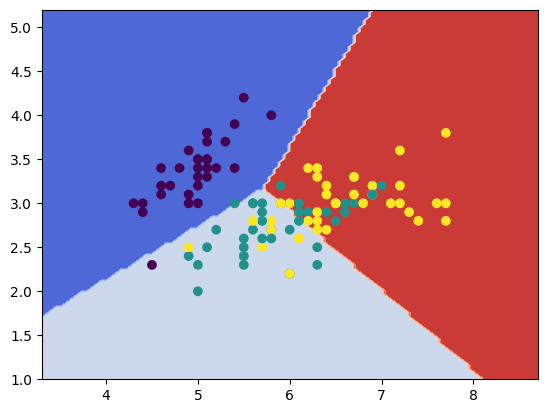

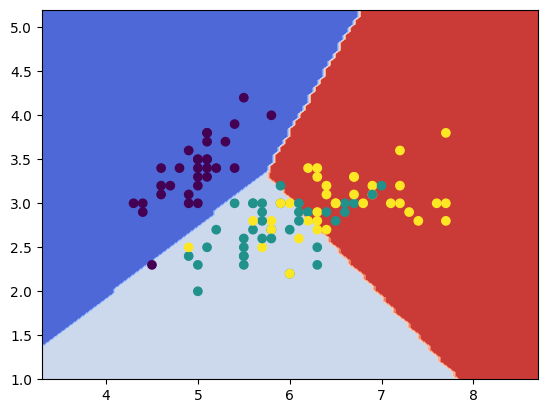

In [32]:
from sklearn.inspection import DecisionBoundaryDisplay
import matplotlib.pyplot as plt 
from sklearn.datasets import load_iris 
iris = load_iris()
X,y = iris.data, iris.target  
X_train, X_test, y_train, y_test = train_test_split(X[:, :2],y, test_size = 0.3, random_state= 42)


lr_ovr = LogisticRegression(multi_class = 'ovr', max_iter = 10000)
lr_ovr.fit(X_train, y_train)

# Fit softmax classifier 
lr_mn = LogisticRegression(multi_class = 'multinomial', max_iter = 100000)
lr_mn.fit(X_train, y_train)


for model in [lr_ovr, lr_mn]:
    DecisionBoundaryDisplay.from_estimator(
        estimator = model, 
        X = X_train , 
        cmap=plt.cm.coolwarm,
        )

    x0 = X_train[:,0]
    x1 = X_train[:,1]
    plt.scatter(x0, x1, c = y_train)

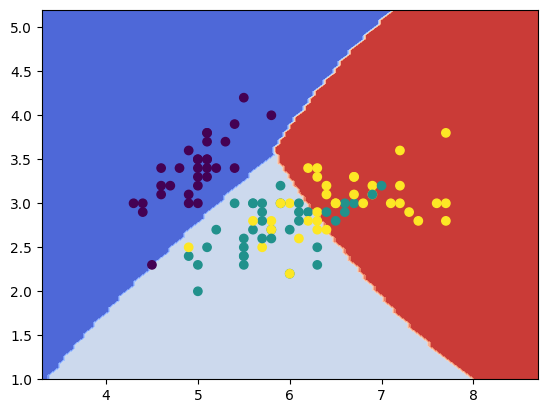

In [34]:
from sklearn.svm import SVC

svm_class_1 = SVC()
svm_class_1.fit(X_train, y_train)

DecisionBoundaryDisplay.from_estimator(
        estimator = svm_class_1, 
        X = X_train , 
        cmap=plt.cm.coolwarm,
        )

x0 = X_train[:,0]
x1 = X_train[:,1]
plt.scatter(x0, x1, c = y_train)